In [ ]:
# Import Useful Libraries
import os
from random import choice
import shutil
import glob
from IPython.display import Image, clear_output
import csv

import cv2
import matplotlib.pyplot as plt

# Dataset

In [ ]:
!unrar x /content/drive/MyDrive/OCR/task_data.rar /content/drive/MyDrive/OCR/task_dataset

#Move two extra files from dataset directory to another path: labels.csv and labels.txt

In [ ]:
source_path = '/content/drive/MyDrive/OCR/task_dataset/task_data/' #dir where images and annotations stored

old_directory = source_path
new_directory = '/content/drive/MyDrive/OCR/trainer/craft/labels_file'
shutil.move(old_directory + '/labels.txt' , new_directory + '/labels.txt')
shutil.move(old_directory + '/labels.csv' , new_directory + '/labels.csv')

# Rename labels 
( ***task_data_0_boxes.txt*** *to* ***gt_task_data_0.txt*** ) 

In [ ]:
def rename_labels(current_file_name : str):
  """
  This function receives labels files and renames them
  """
  if current_file_name[-1] != '/':
    current_file_name = current_file_name + '/'

  for (root,dirs,files) in os.walk(current_file_name):
    for file in files:
      if file.endswith('.txt'):
        os.rename(current_file_name + file, current_file_name + 'gt_' + ''.join(file.split('_boxes')))
      else:
        continue 

rename_labels(source_path)        

#Label Preparation

In [ ]:
def change_label_content(path : str, path_csv="/content/drive/MyDrive/OCR/trainer/craft/labels_file/labels.csv"): 
  """
  This function receives labels and csv directory of labels and changes the content format of labels.
  """
  img_text = []
  with open(path_csv) as file:
    csvreader = csv.reader(file)
    
    for row in csvreader:
      img_text.append(row[1]) #store text of images into list from csv file
  

    txt_files = glob.glob(path + '/*.txt') 
    
    for i in range(len(txt_files)): 
      col1 = []
      col2 = []
      col3 = []
      col4 = []
          
      with open(path + f'/gt_task_data_{i}.txt') as f: #finding coordinates of 4 edges of the bounding box
        for line in f:
          col1.append(int(line.split()[0]))
          col2.append(int(line.split()[1]))
          col3.append(int(line.split()[2]))
          col4.append(int(line.split()[3]))
         
      x1 = min(col1)
      y1 = min(col2)
      x2 = max(col3)
      y2 = max(col4)


      with open(path + f'/gt_task_data_{i}.txt', 'w') as f:
        f.write(f'{x1},{y2},{x2},{y2},{x2},{y1},{x1},{y1}')
        f.write(',' + img_text[i + 1])  

In [ ]:
dir = '/content/drive/MyDrive/OCR/task_dataset/task_data/'
change_label_content(dir)

#train_test_split

In [ ]:
#Arrays to store file names
imgs =[]
xmls =[]

source_path = "/content/drive/MyDrive/OCR/task_dataset/task_data"
#Soring files to corresponding arrays
for (dirname, dirs, files) in os.walk(source_path):
    for filename in files:
        if filename.endswith('.txt'):
            xmls.append(filename)
        elif filename.endswith('.jpg'):
            imgs.append(filename)
        else:
          continue    


#Setup ratio (val ratio = rest of the files in origin dir after splitting into train and test)
train_ratio = 0.8
val_ratio = 0.2

#Counting range for cycles
count_train = int(len(imgs)*train_ratio)
count_val = int(len(imgs)*val_ratio)
print("training images are : ",count_train)
print("Validation images are : ",count_val)



train_img_path = '/content/drive/MyDrive/OCR/trainer/craft/data_root_dir/ch4_training_images/'
val_img_path = '/content/drive/MyDrive/OCR/trainer/craft/data_root_dir/ch4_test_images/'
source_path = '/content/drive/MyDrive/OCR/task_dataset/task_data/' #dir where images and annotations stored

train_label_path = '/content/drive/MyDrive/OCR/trainer/craft/data_root_dir/ch4_training_localization_transcription_gt/'
val_label_path = '/content/drive/MyDrive/OCR/trainer/craft/data_root_dir/ch4_test_localization_transcription_gt/'

#Cycle for train dir
for x in range(count_train):

    file_jpg = choice(imgs) # get name of random image from origin dir
    file_xml = 'gt_' + file_jpg[:-4] +'.txt' # get name of corresponding annotation file

    shutil.copy(os.path.join(source_path, file_jpg), os.path.join(train_img_path, file_jpg))
    shutil.copy(os.path.join(source_path, file_xml), os.path.join(train_label_path, file_xml))

    #remove files from arrays
    imgs.remove(file_jpg)
    xmls.remove(file_xml)

#Cycle for val dir   
for x in range(count_val):

    file_jpg = choice(imgs) # get name of random image from origin dir
    file_xml = 'gt_' + file_jpg[:-4] +'.txt' # get name of corresponding annotation file

    shutil.copy(os.path.join(source_path, file_jpg), os.path.join(val_img_path, file_jpg))
    shutil.copy(os.path.join(source_path, file_xml), os.path.join(val_label_path, file_xml))
    
    #remove files from arrays
    imgs.remove(file_jpg)
    xmls.remove(file_xml)

#Test an image

D C B A


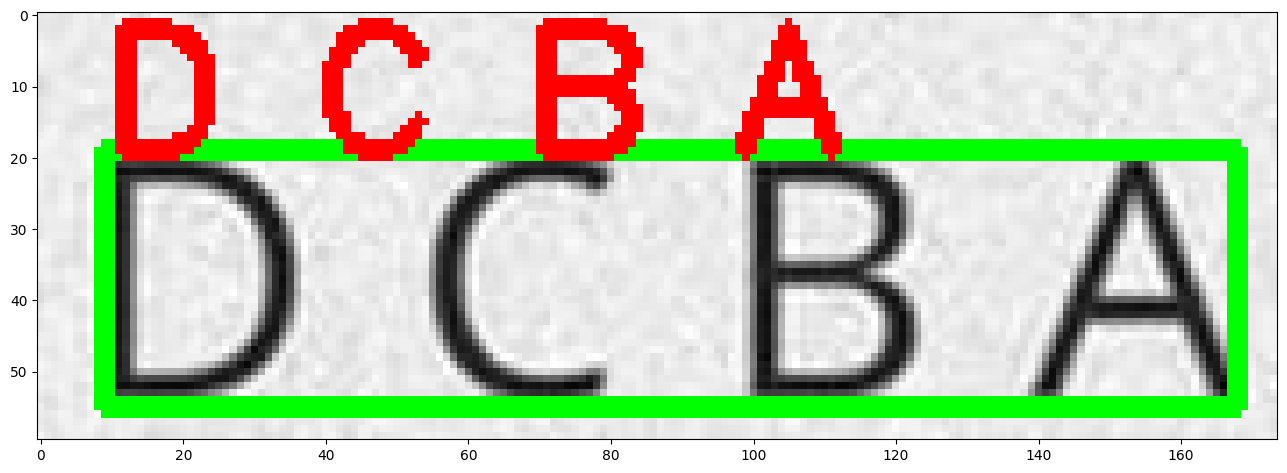

In [ ]:
path_txt = '/content/drive/MyDrive/OCR/task_dataset/task_data/gt_task_data_0.txt'
with open(path_txt) as f:
  for line in f:
    x1, y2, x2, y2, x2, y1, x1, y1, text = line.split(',')
    x1, y2, x2, y2, x2, y1, x1, y1 = int(x1), int(y2), int(x2), int(y2), int(x2), int(y1), int(x1), int(y1)
    print(text)

path_img = '/content/drive/MyDrive/OCR/task_dataset/task_data/task_data_0.jpg'
image = cv2.imread(path_img)

cv2.rectangle(image,(x1, y1) ,(x2, y2), (0, 255, 0), 2)
cv2.putText(image,text,(x1, y1),cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 0, 0), 2)
plt.rcParams['figure.figsize'] = (16,16)
plt.imshow(image);    

#Imbalance Data

In [ ]:
import pandas as pd

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/OCR/trainer/craft/labels_file/labels.csv', index_col=0)
df

,words
filename,
./task_data_0.jpg,D C B A
./task_data_1.jpg,H G F E
./task_data_2.jpg,M L K J I
./task_data_3.jpg,S R Q P O N
./task_data_4.jpg,W V U T
...,...
./task_data_765.jpg,زیاس ٣ یپوت راد هیاپ فافش
./task_data_766.jpg,هداس کیراب یملق عیام یعمش اج تس
./task_data_767.jpg,زیاس ٣ فافش هشیش هناوتسا


In [ ]:
df.describe()

,words
count,770
unique,448
top,اراک یتاه
freq,8


In [ ]:
df.value_counts()

words                   
وپماش زردلوشدناده           8
هروشدض وپماش زردلوشدناده    8
اراک یتاه                   8
وپماش مردوردیه              6
وج اراک یتاه                6
                           ..
کچوک لاگنچ و وقاچ تس        1
کچوک یروخ هویم وقاچ تس      1
گ 100 زمرق لفلف هراتس       1
گ 100 هتساشن هراتس          1
0044 نامریا راد حرط یگنر    1
Length: 448, dtype: int64

In [ ]:
df['words'].dtype

dtype('O')

In [ ]:
# All characters in the string are alphanumeric
df.words.apply(lambda x : ''.join(x.split()).isalnum()).value_counts()

True     722
False     48
Name: words, dtype: int64

In [ ]:
# All characters in a string are alphabetic
df.words.apply(lambda x: ''.join(x.split()).isalpha()).value_counts()

True     396
False    374
Name: words, dtype: int64

In [ ]:
# All characters in a string are digits or Unicode char of a digit
df.words.apply(lambda x: ''.join(x.split()).isdigit()).value_counts()

False    763
True       7
Name: words, dtype: int64

In [ ]:
# All characters in the string are ASCII
df.words.apply(lambda x: ''.join(x.split()).isascii()).value_counts()

False    726
True      44
Name: words, dtype: int64

In [ ]:
# Find cases with 1, 0, \ at the beginning or end of the text
def one_dash_zero(text):
  if text[0] == '1' or text[-1] == '1':
    return text

  if text[0] == '0' or text[-1] == '0':
    return text

  if text[0] == '/' or text[-1] == '/':
    return text

  if text[0] == '١' or text[-1] == '١':
    return text
df.words.apply(one_dash_zero).value_counts().sum()   

16

#Histogram of dataset

In [ ]:
from PIL import Image
import cv2
import matplotlib.pyplot as plt
import numpy as np
from google.colab.patches import cv2_imshow
!curl -o logo.png https://colab.research.google.com/img/colab_favicon_256px.png


  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  4534  100  4534    0     0  26057      0 --:--:-- --:--:-- --:--:-- 26057


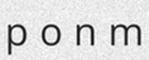

In [ ]:
img = Image.open('/content/drive/MyDrive/OCR/task_dataset/task_data/task_data_9.jpg')
img.show()

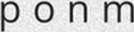

In [ ]:
# Crop extra background
path_txt = '/content/drive/MyDrive/OCR/task_dataset/task_data/gt_task_data_9.txt'
with open(path_txt) as f:
  for line in f:
    x1, y2, x2, y2, x2, y1, x1, y1, _ = line.split(',')
    x1, y2, x2, y2, x2, y1, x1, y1 = int(x1), int(y2), int(x2), int(y2), int(x2), int(y1), int(x1), int(y1)
    box = (x1, y1, x2, y2)    
img2 = img.crop(box)
img2.save('/content/drive/MyDrive/OCR/trainer/craft/data_root_dir/ch4_training_images/task_data_cropped_9.jpg')
img2.show()

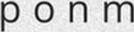

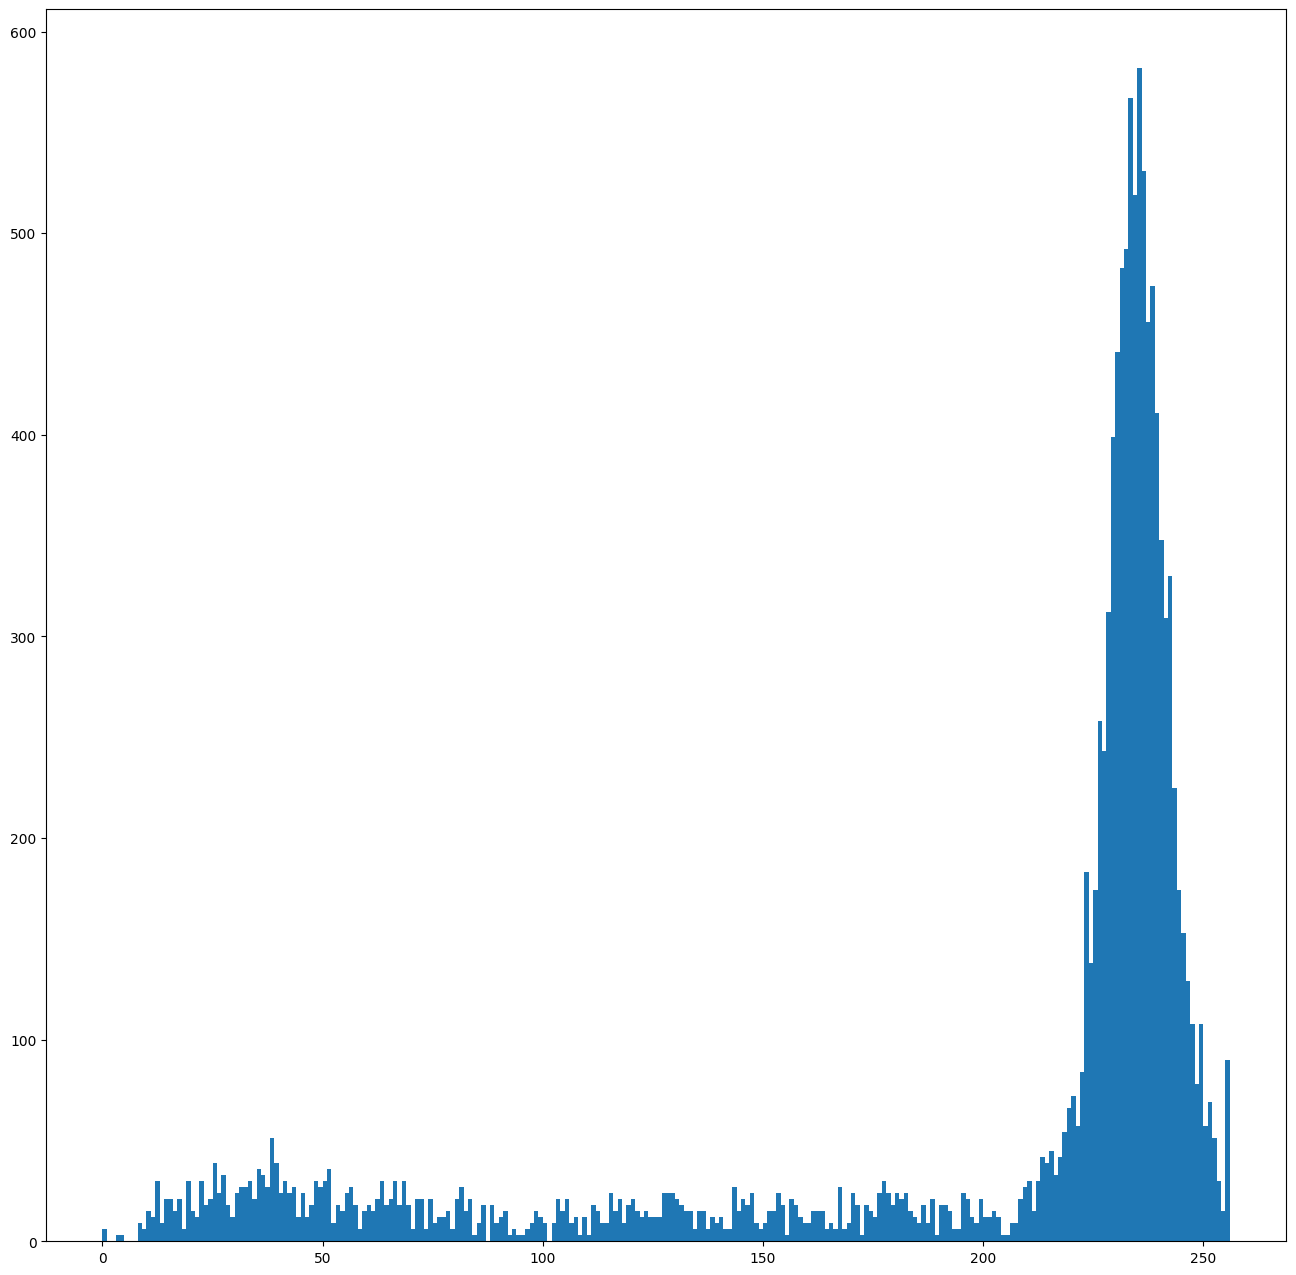

In [ ]:
# Image Histogram
img = cv2.imread("/content/drive/MyDrive/OCR/trainer/craft/data_root_dir/ch4_training_images/task_data_cropped_9.jpg")
# img = cv2.resize(img, (0, 0), fx = 0.5, fy = 0.5)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
cv2_imshow(img) 
hist = cv2.calcHist([img],[0],None,[256],[0,256])
plt.hist(img.ravel(),256,[0,256])
plt.show();